In [1]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 1 – Imports & notebook‑wide configuration
# ────────────────────────────────────────────────────────────────────────────
import json
from pathlib import Path
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 120   # sharper plots in most notebooks
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False



Bad key keymap.all_axes in file /mnt/xarfuse/uid-694457/1ba7511b-seed-nspid4026531836_cgpid167533-ns-4026531841/bento/server/matplotlibrc-3.1.3, line 76 ('keymap.all_axes : a                 # enable all axes')
You probably need to get an updated matplotlibrc file from
https://github.com/matplotlib/matplotlib/blob/v3.10.3/lib/matplotlib/mpl-data/matplotlibrc
or from the matplotlib source distribution


In [2]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 2 – Load all six JSONL files into one DataFrame
# ────────────────────────────────────────────────────────────────────────────

# ‼️  EDIT THIS LIST  ‼️  ----------------------------------------------------
jsonl_paths = [
    Path("/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/aokvqa/aokvqa_search_annotated.jsonl"),
    Path("/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/okvqa/okvqa_search_annotated.jsonl"),
    Path("/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/textvqa/textvqa_search_annotated.jsonl"),
    Path("/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/webqa/webqa_search_annotated.jsonl"),
]
# ---------------------------------------------------------------------------

records = []
for f in jsonl_paths:
    with f.open("r", encoding="utf‑8") as fp:
        records.extend(json.loads(line) for line in fp)

df = pd.json_normalize(records)
print(f"✔ Loaded {len(df):,} rows from {len(jsonl_paths)} files")
df.head(2)


✔ Loaded 800 rows from 4 files


,id,dataset,image_path,question,needs_retrieval,needs_rationale,answer_draft,num_search_toks,is_decomposed,decomposed_questions,decomposed_rationale,decomposed_needs_retrieval,mc_choices,ground_truth,rationales,search_calls,decomp_mismatch_cnt,image_gold_retrieved,text_gold_retrieved
0,aokvqa-22MexNkBPpdZGX6sxbxVBH,aokvqa,[/home/jeonghkim/projects/region-mm-retrieve/d...,What is the man by the bags awaiting?,False,the question asks about the man's intentions o...,the man by the bags is likely waiting for some...,0,False,[],the question asks about the man's intentions o...,[],"[skateboarder, train, delivery, cab]","['ride', 'ride', 'bus', 'taxi', 'travelling', ...","[A train would not be on the street, he would ...",[],NaN,NaN,NaN
1,aokvqa-22ZAvqke8EhGDj8e4eyios,aokvqa,[/home/jeonghkim/projects/region-mm-retrieve/d...,Where does this man eat pizza?,False,the question is asking about the location wher...,the man in the image appears to be eating pizz...,0,False,[],,[],"[office, cafe, motel, outside]","['work', 'office', 'work', 'work', 'at work', ...",[The man is eating pizza at a work desk in an ...,[],NaN,NaN,NaN


In [3]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 3 – Derive helper columns we’ll need repeatedly
# ────────────────────────────────────────────────────────────────────────────
df["n_decomp_qs"]       = df["decomposed_questions"].apply(len)
df["n_search_toks"]     = df["num_search_toks"]          # already numeric
df["has_search_calls"]  = df["search_calls"].apply(bool) # True/False

# Flatten out qtype information for global counts
qtype_counter = Counter()
for calls in df["search_calls"]:
    qtype_counter.update(call["qtype"] for call in calls)  # safe on []

qtype_df = (pd.Series(qtype_counter, name="count")
              .reindex(["REGION", "IMAGE", "TEXT"])  # consistent order
              .fillna(0)
              .astype(int)
              .rename_axis("qtype")
              .reset_index())
qtype_df


,qtype,count
0,REGION,368
1,IMAGE,73
2,TEXT,317


In [4]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 4 – Print all requested scalar statistics
# ────────────────────────────────────────────────────────────────────────────
def print_bar(title, series):
    print(f"\n\u2500\u2500 {title}")
    for k, v in series.items():
        print(f"   {k:<15}: {v:,}")

# (i) needs_retrieval
print_bar("(i) needs_retrieval", df["needs_retrieval"].value_counts())

# (ii) is_decomposed
print_bar("(ii) is_decomposed", df["is_decomposed"].value_counts())

# (iii) # of decomposed questions
print(f"\n\u2500\u2500 (iii) total decomposed sub‑questions : {df['n_decomp_qs'].sum():,}")

# (iv) # of search tokens in answer_draft
print(f"\u2500\u2500 (iv) total <search> tokens          : {df['n_search_toks'].sum():,}")

# (v) # per qtype
print_bar("(v) search‑call qtypes", qtype_df.set_index("qtype")["count"])

# (vi) # of instances from each dataset
print_bar("(vi) dataset split", df["dataset"].value_counts())



── (i) needs_retrieval
   1              : 428
   0              : 372

── (ii) is_decomposed
   1              : 429
   0              : 371

── (iii) total decomposed sub‑questions : 825
── (iv) total <search> tokens          : 751

── (v) search‑call qtypes
   REGION         : 368
   IMAGE          : 73
   TEXT           : 317

── (vi) dataset split
   aokvqa         : 200
   okvqa          : 200
   textvqa        : 200
   webqa          : 200


findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.


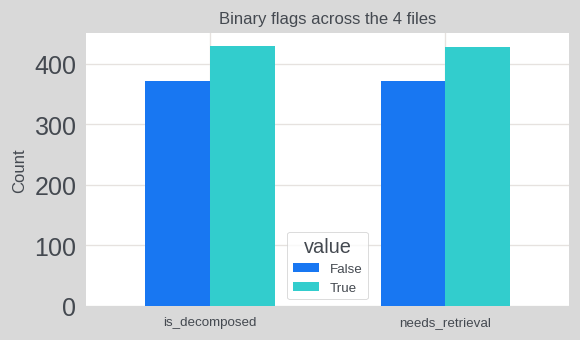

In [5]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 5 – Plot: needs_retrieval & is_decomposed  (refactored)
# ────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 3))

(df[["needs_retrieval", "is_decomposed"]]
     .melt()
     .value_counts()
     .rename_axis(["variable", "value"])
     .reset_index(name="count")
     .pivot(index="variable", columns="value", values="count")
     .plot(kind="bar", ax=ax, legend=True, width=0.55))   # thinner bars

# Axis cosmetics
ax.set_ylabel("Count", fontsize=10)
ax.set_xlabel("")
ax.set_title("Binary flags across the 4 files", fontsize=10)

# horizontal, smaller labels
ax.set_xticklabels(ax.get_xticklabels(),
                   rotation=0,            # 0° = horizontal
                   ha="center",
                   fontsize=8)            # smaller font

ax.legend(title="value", labels=["False", "True"], fontsize=8)
plt.tight_layout()


findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.


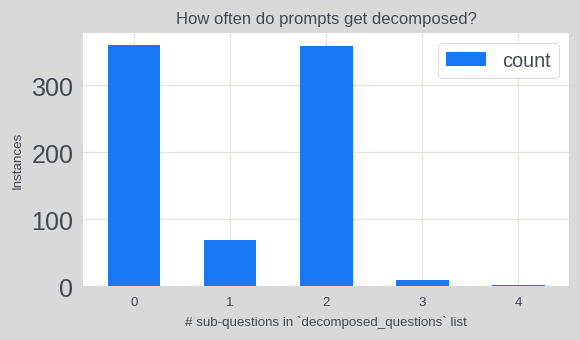

In [12]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 6 – Plot: distribution of decomposed‑question counts
# ────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 3))
(df["n_decomp_qs"]
   .value_counts()
   .sort_index()
   .plot(kind="bar", ax=ax, legend=True, width=0.55))
ax.set_xlabel("# sub-questions in `decomposed_questions` list", fontsize=8)
ax.set_xticklabels(ax.get_xticklabels(),
                   rotation=0,            # 0° = horizontal
                   ha="center",
                   fontsize=8)            # smaller font

ax.set_ylabel("Instances", fontsize=8)
ax.set_title("How often do prompts get decomposed?", fontsize=10)
plt.tight_layout()


findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.


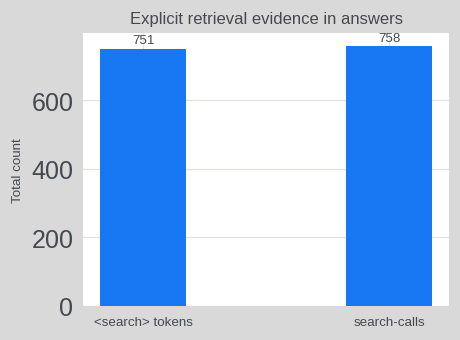

In [16]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 7 – Plot: total <search> tokens vs. # search-call objects  (refactored)
# ────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(4, 3))

labels   = ["<search> tokens", "search-calls"]
heights  = [df["n_search_toks"].sum(), qtype_df["count"].sum()]

ax.bar(labels, heights, width=0.35)          # thinner bars

# axis titles & labels
ax.set_ylabel("Total count", fontsize=8)
ax.set_title("Explicit retrieval evidence in answers", fontsize=10)

# horizontal, smaller tick labels
ax.set_xticklabels(labels, rotation=0, ha="center", fontsize=8)

# add numeric annotations just above each bar
for i, v in enumerate(heights):
    ax.text(i, v + max(heights)*0.02, f"{v:,}", ha="center", fontsize=8)

plt.tight_layout()

findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.


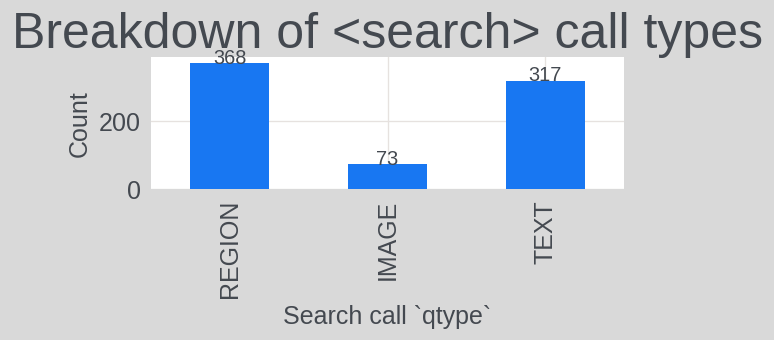

In [17]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 8 – Plot: qtype mix (REGION, IMAGE, TEXT)  (refactored)
# ────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 3))

# draw bars – explicit bar call gives tighter control than pd.DataFrame.plot
ax.bar(qtype_df["qtype"], qtype_df["count"], width=0.55)

# axis titles & labels
ax.set_xlabel("Search-call `qtype`", fontsize=8)
ax.set_ylabel("Count", fontsize=8)
ax.set_title("Break-down of <search> call types", fontsize=10)

# horizontal, smaller tick labels
ax.set_xticklabels(qtype_df["qtype"], rotation=0, ha="center", fontsize=8)

# numeric annotations above each bar
for p in ax.patches:
    ax.text(p.get_x() + p.get_width() / 2,
            p.get_height() + 1,
            f"{int(p.get_height()):,}",
            ha="center",
            fontsize=8)

plt.tight_layout()


findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.
findfont: Font family 'Noto Sans TC' not found.
findfont: Font family 'Noto Sans SC' not found.
findfont: Font family 'Noto Naskh Arabic UI' not found.
findfont: Font family 'Noto Sans UI' not found.


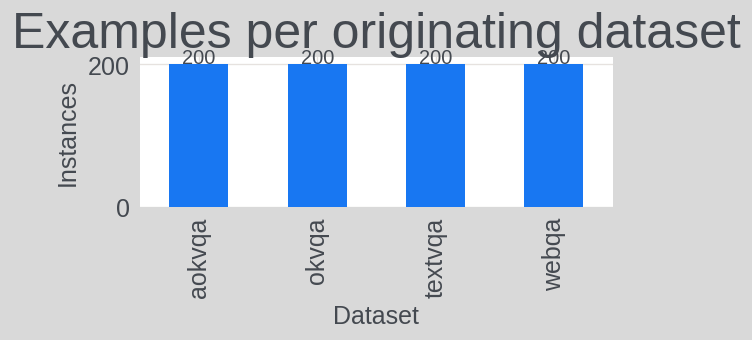

In [18]:
# ────────────────────────────────────────────────────────────────────────────
# Cell 9 – Plot: dataset composition
# ────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(5, 3))
(df["dataset"].value_counts()
   .plot(kind="bar", ax=ax))
ax.set_xlabel("Dataset")
ax.set_ylabel("Instances")
ax.set_title("Examples per originating dataset")
for p in ax.patches:
    ax.text(p.get_x() + p.get_width()/2, p.get_height() + 1,
            f"{int(p.get_height()):,}", ha="center")
plt.tight_layout()
